## Step 1: Check the GPU

In [ ]:
import torch

print("PyTorch version:", torch.__version__)

if torch.cuda.is_available():
    print("✅ GPU found:", torch.cuda.get_device_name(0))
else:
    print("❌ No GPU found! Go to Runtime > Change runtime type > T4 GPU, then run again.")

PyTorch version: 2.11.0+cu130
✅ GPU found: Tesla T4


## Step 2: Import libraries

In [ ]:
import os
import json
import time
import copy
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Use the GPU if we have one, otherwise the CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Fix the random seeds so results are repeatable
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

Using device: cuda


## Step 3: Settings (you can change these)

Everything you might want to change is in this one cell.

In [ ]:
# ---------- Which models to train ----------
# Choose from: "resnet18", "mobilenet_v2", "efficientnet_b0"
# More models = more training time (about 10-15 min per model on a T4 GPU)
MODELS_TO_TRAIN = ["resnet18", "mobilenet_v2"]

# ---------- Image and batch size ----------
IMAGE_SIZE = 128        # every image is resized to 128 x 128
BATCH_SIZE = 64         # if you get "CUDA out of memory", change this to 32

# ---------- Training length ----------
HEAD_EPOCHS = 5         # Phase 1: train only the new last layer
FINE_TUNE_EPOCHS = 15   # Phase 2: fine-tune the whole model
HEAD_LR = 1e-3          # learning rate for phase 1
FINE_TUNE_LR = 1e-4     # learning rate for phase 2 (smaller = gentler)
PATIENCE = 5            # stop phase 2 early if val accuracy does not improve for 5 epochs

# ---------- Data split ----------
VAL_SPLIT = 0.2         # 20% of the train images are used as validation (same as your first notebook)

# ---------- Class weights ----------
USE_CLASS_WEIGHTS = True   # True = rare emotions (like disgust) get more importance

# ---------- Other ----------
USE_PRETRAINED = True   # keep True. (False = no transfer learning, only for testing the code)
SAVE_FOLDER = "/content/emotion_models"   # all trained models will be saved here
os.makedirs(SAVE_FOLDER, exist_ok=True)

## Step 4: Download the dataset (FER2013 from Kaggle)

Same dataset as your first notebook. It downloads straight into Colab, so you do not need to upload anything.

In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download("msambare/fer2013")
print("Dataset downloaded to:", dataset_path)
print("Inside it:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset downloaded to: /kaggle/input/fer2013
Inside it: ['test', 'train']


## Step 5: Set the train / test folders and count the images

In [ ]:
train_dir = os.path.join(dataset_path, "train")
test_dir = os.path.join(dataset_path, "test")

assert os.path.exists(train_dir), "train folder not found. Look at the 'Inside it' list printed above."
assert os.path.exists(test_dir), "test folder not found. Look at the 'Inside it' list printed above."

for split_name, split_dir in [("TRAIN", train_dir), ("TEST", test_dir)]:
    print(split_name)
    for emotion in sorted(os.listdir(split_dir)):
        emotion_dir = os.path.join(split_dir, emotion)
        if os.path.isdir(emotion_dir):
            print(f"   {emotion:10s} {len(os.listdir(emotion_dir))}")

TRAIN
   angry      3995
   disgust    436
   fear       4097
   happy      7215
   neutral    4965
   sad        4830
   surprise   3171
TEST
   angry      958
   disgust    111
   fear       1024
   happy      1774
   neutral    1233
   sad        1247
   surprise   831


## Step 6: Remove corrupted images (if any)

In [ ]:
from PIL import UnidentifiedImageError

corrupted_files = []
for split_dir in [train_dir, test_dir]:
    for emotion in os.listdir(split_dir):
        emotion_dir = os.path.join(split_dir, emotion)
        if not os.path.isdir(emotion_dir):
            continue
        for file_name in os.listdir(emotion_dir):
            file_path = os.path.join(emotion_dir, file_name)
            try:
                with Image.open(file_path) as img:
                    img.verify()
            except (UnidentifiedImageError, OSError, SyntaxError):
                corrupted_files.append(file_path)

print("Corrupted images found:", len(corrupted_files))
for file_path in corrupted_files:
    os.remove(file_path)

# successfully executed this cell : Output was - There is no corrupted images in this dataset

KeyboardInterrupt: 

## Step 7: Data transforms (augmentation)

- Images are turned into 3-channel (the pretrained model expects colour images).
- **Training images** get small random changes (flip, rotate, shift, brightness). This stops the model from just memorising the pictures (overfitting).
- **Validation / test images** are only resized and normalised (no random changes).

In [ ]:
# Numbers the pretrained ImageNet models expect
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
    transforms.RandomErasing(p=0.2),
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
print("Transforms ready ✅")

Transforms ready ✅


## Step 8: Create train / validation / test sets

The dataset already has `train` and `test` folders. We take 20% of the train images as **validation** (used during training to pick the best epoch). The **test** images are used only once at the very end.

In [ ]:
# Two copies of the train folder: one with augmentation, one without
train_data_aug = datasets.ImageFolder(train_dir, transform=train_transform)
train_data_plain = datasets.ImageFolder(train_dir, transform=eval_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=eval_transform)

class_names = train_data_aug.classes
num_classes = len(class_names)
assert test_dataset.classes == class_names, "Train and test folders have different emotion names!"
print("Classes:", class_names)

# split train -> train + validation (stratified = every emotion is split in the same proportion)
all_indices = np.arange(len(train_data_plain))
train_indices, val_indices = train_test_split(
    all_indices, test_size=VAL_SPLIT, random_state=SEED, stratify=train_data_plain.targets
)

train_dataset = Subset(train_data_aug, train_indices)     # with augmentation
val_dataset = Subset(train_data_plain, val_indices)       # without augmentation

print("Train images:", len(train_dataset))
print("Val images  :", len(val_dataset))
print("Test images :", len(test_dataset))

# ----- data loaders (they give the model one batch at a time) -----
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# ----- class weights: rare emotions get a bigger weight -----
train_labels = np.array(train_data_plain.targets)[train_indices]
class_counts = np.bincount(train_labels, minlength=num_classes)

if USE_CLASS_WEIGHTS:
    weights = (class_counts.sum() / (num_classes * class_counts)) ** 0.5   # square root keeps it gentle
    class_weights = torch.tensor(weights, dtype=torch.float).to(device)
    print()
    for name, w in zip(class_names, weights):
        print(f"weight for {name:10s}: {w:.2f}")
else:
    class_weights = None

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Train images: 22967
Val images  : 5742
Test images : 7178

weight for angry     : 1.01
weight for disgust   : 3.07
weight for fear      : 1.00
weight for happy     : 0.75
weight for neutral   : 0.91
weight for sad       : 0.92
weight for surprise  : 1.14


### Look at the data: how many images per emotion?

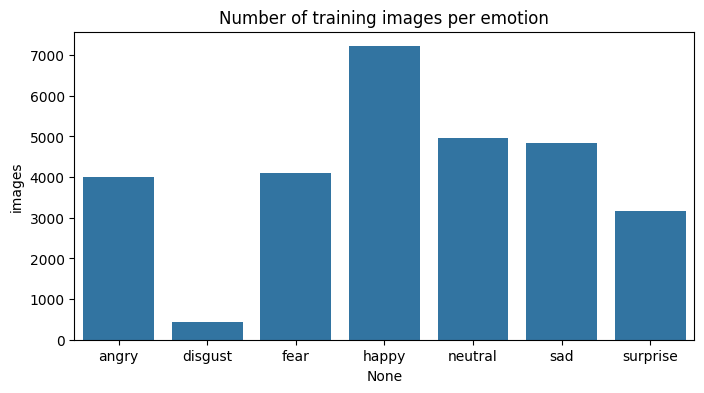

angry       3995
disgust      436
fear        4097
happy       7215
neutral     4965
sad         4830
surprise    3171
Name: count, dtype: int64


In [ ]:
# count images per class in the train folder
counts = pd.Series(train_data_plain.targets).value_counts().sort_index()
counts.index = [class_names[i] for i in counts.index]

plt.figure(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.title("Number of training images per emotion")
plt.ylabel("images")
plt.show()
print(counts)

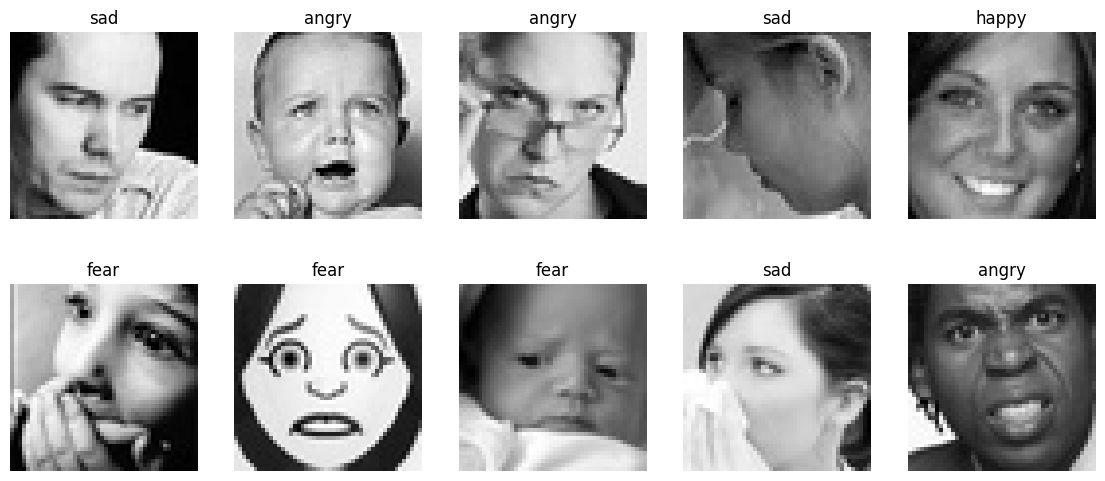

In [ ]:
# show 10 random training images
plt.figure(figsize=(14, 6))
for i in range(10):
    idx = random.randint(0, len(train_data_plain) - 1)
    path, label = train_data_plain.samples[idx]
    plt.subplot(2, 5, i + 1)
    plt.imshow(Image.open(path).convert("L"), cmap="gray")
    plt.title(class_names[label])
    plt.axis("off")
plt.show()

## Step 9: Train all models 🚀

This is the main cell. For **each model** in `MODELS_TO_TRAIN` it will:
1. Load the pretrained model and replace its last layer with one for our emotions
2. **Phase 1** → train only the last layer
3. **Phase 2** → fine-tune the whole model
4. Keep the **best** version (highest validation accuracy) and save it
5. Test it on the test set (images the model never saw)

You will see the loss and accuracy printed after every epoch.

In [ ]:
loss_function = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)   # weights help rare emotions, smoothing helps noisy labels
use_amp = (device.type == "cuda")                          # mixed precision = faster on GPU
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

results = []          # final test results of every model
all_histories = {}    # training history of every model (for the graphs)
all_predictions_by_model = {}   # test predictions of every model (for the confusion matrix)

for model_name in MODELS_TO_TRAIN:
    print("=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    # ---------- 1) build the pretrained model with a new last layer ----------
    if model_name == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT if USE_PRETRAINED else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(model.fc.in_features, num_classes))
        new_layer = model.fc

    elif model_name == "mobilenet_v2":
        weights = models.MobileNet_V2_Weights.DEFAULT if USE_PRETRAINED else None
        model = models.mobilenet_v2(weights=weights)
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(model.last_channel, num_classes))
        new_layer = model.classifier

    elif model_name == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.DEFAULT if USE_PRETRAINED else None
        model = models.efficientnet_b0(weights=weights)
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(model.classifier[1].in_features, num_classes))
        new_layer = model.classifier

    else:
        print("Unknown model name:", model_name, "-> skipping")
        continue

    model = model.to(device)

    # freeze everything, then un-freeze only the new last layer
    for param in model.parameters():
        param.requires_grad = False
    for param in new_layer.parameters():
        param.requires_grad = True

    # ---------- 2) train in 2 phases ----------
    phases = [
        ("Phase 1: train only the new last layer", HEAD_EPOCHS, HEAD_LR, False),
        ("Phase 2: fine-tune the whole model", FINE_TUNE_EPOCHS, FINE_TUNE_LR, True),
    ]

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())
    start_time = time.time()

    for phase_name, num_epochs, learning_rate, unfreeze_all in phases:
        print()
        print("-" * 70)
        print(phase_name)
        print("-" * 70)

        if unfreeze_all:
            for param in model.parameters():
                param.requires_grad = True

        optimizer = torch.optim.AdamW(
            [p for p in model.parameters() if p.requires_grad],
            lr=learning_rate, weight_decay=1e-2
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
        epochs_without_improvement = 0

        for epoch in range(num_epochs):
            # ----- training -----
            model.train()
            running_loss, running_correct, running_total = 0.0, 0, 0

            for images, labels in train_loader:
                images, labels = images.to(device), labels.to(device)

                optimizer.zero_grad()
                with torch.autocast(device_type=device.type, enabled=use_amp):
                    outputs = model(images)
                    loss = loss_function(outputs, labels)

                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

                running_loss += loss.item() * images.size(0)
                running_correct += (outputs.argmax(1) == labels).sum().item()
                running_total += images.size(0)

            train_loss = running_loss / running_total
            train_acc = running_correct / running_total

            # ----- validation (no learning here) -----
            model.eval()
            running_loss, running_correct, running_total = 0.0, 0, 0

            with torch.no_grad():
                for images, labels in val_loader:
                    images, labels = images.to(device), labels.to(device)
                    with torch.autocast(device_type=device.type, enabled=use_amp):
                        outputs = model(images)
                        loss = loss_function(outputs, labels)
                    running_loss += loss.item() * images.size(0)
                    running_correct += (outputs.argmax(1) == labels).sum().item()
                    running_total += images.size(0)

            val_loss = running_loss / running_total
            val_acc = running_correct / running_total

            scheduler.step()

            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["train_acc"].append(train_acc)
            history["val_acc"].append(val_acc)

            # ----- keep the best model -----
            note = ""
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_weights = copy.deepcopy(model.state_dict())
                torch.save(best_weights, f"{SAVE_FOLDER}/{model_name}_best.pth")   # saved right away, in case Colab disconnects
                epochs_without_improvement = 0
                note = "  ⭐ best so far (saved)"
            else:
                epochs_without_improvement += 1

            print(f"Epoch {epoch + 1:2d}/{num_epochs}  "
                  f"train loss {train_loss:.3f} acc {train_acc * 100:5.2f}%  |  "
                  f"val loss {val_loss:.3f} acc {val_acc * 100:5.2f}%{note}")

            # early stopping (only in phase 2)
            if unfreeze_all and epochs_without_improvement >= PATIENCE:
                print("No improvement for", PATIENCE, "epochs -> stopping this phase early")
                break

    minutes = (time.time() - start_time) / 60
    print(f"\nTraining finished in {minutes:.1f} minutes. Best val accuracy: {best_val_acc * 100:.2f}%")

    # ---------- 3) test the best version on the test set ----------
    model.load_state_dict(best_weights)
    model.eval()

    all_predictions, all_labels = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            all_predictions.extend(outputs.argmax(1).cpu().numpy())
            all_labels.extend(labels.numpy())

    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    test_acc = (all_predictions == all_labels).mean()
    print(f"🎯 TEST ACCURACY of {model_name}: {test_acc * 100:.2f}%")

    # ---------- 4) save the final model file ----------
    # This file has the weights AND everything needed to use the model later
    torch.save({
        "model_name": model_name,
        "model_state_dict": best_weights,
        "class_names": class_names,
        "image_size": IMAGE_SIZE,
        "imagenet_mean": imagenet_mean,
        "imagenet_std": imagenet_std,
        "val_accuracy": best_val_acc,
        "test_accuracy": float(test_acc),
    }, f"{SAVE_FOLDER}/{model_name}_final.pth")

    results.append({
        "model": model_name,
        "val_accuracy_%": round(best_val_acc * 100, 2),
        "test_accuracy_%": round(test_acc * 100, 2),
        "train_minutes": round(minutes, 1),
    })
    all_histories[model_name] = history
    all_predictions_by_model[model_name] = (all_labels, all_predictions)

print("\nAll models trained ✅")

MODEL: resnet18
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]



----------------------------------------------------------------------
Phase 1: train only the new last layer
----------------------------------------------------------------------
Epoch  1/5  train loss 2.016 acc 26.61%  |  val loss 1.851 acc 36.38%  ⭐ best so far (saved)
Epoch  2/5  train loss 1.911 acc 31.14%  |  val loss 1.833 acc 37.25%  ⭐ best so far (saved)
Epoch  3/5  train loss 1.888 acc 32.16%  |  val loss 1.808 acc 38.04%  ⭐ best so far (saved)
Epoch  4/5  train loss 1.871 acc 33.09%  |  val loss 1.809 acc 38.45%  ⭐ best so far (saved)
Epoch  5/5  train loss 1.865 acc 33.50%  |  val loss 1.801 acc 38.85%  ⭐ best so far (saved)

----------------------------------------------------------------------
Phase 2: fine-tune the whole model
----------------------------------------------------------------------
Epoch  1/15  train loss 1.618 acc 48.62%  |  val loss 1.437 acc 58.41%  ⭐ best so far (saved)
Epoch  2/15  train loss 1.450 acc 57.36%  |  val loss 1.356 acc 62.05%  ⭐ best so

100%|██████████| 13.6M/13.6M [00:00<00:00, 72.3MB/s]



----------------------------------------------------------------------
Phase 1: train only the new last layer
----------------------------------------------------------------------
Epoch  1/5  train loss 1.894 acc 30.84%  |  val loss 1.807 acc 37.77%  ⭐ best so far (saved)
Epoch  2/5  train loss 1.855 acc 34.01%  |  val loss 1.796 acc 38.21%  ⭐ best so far (saved)
Epoch  3/5  train loss 1.842 acc 35.06%  |  val loss 1.794 acc 38.49%  ⭐ best so far (saved)
Epoch  4/5  train loss 1.836 acc 35.12%  |  val loss 1.779 acc 38.89%  ⭐ best so far (saved)
Epoch  5/5  train loss 1.826 acc 35.76%  |  val loss 1.779 acc 38.38%

----------------------------------------------------------------------
Phase 2: fine-tune the whole model
----------------------------------------------------------------------
Epoch  1/15  train loss 1.713 acc 42.83%  |  val loss 1.571 acc 51.36%  ⭐ best so far (saved)
Epoch  2/15  train loss 1.573 acc 50.76%  |  val loss 1.494 acc 55.05%  ⭐ best so far (saved)
Epoch  3/1

## Step 10: Compare the models

In [ ]:
results_table = pd.DataFrame(results).sort_values("test_accuracy_%", ascending=False).reset_index(drop=True)
results_table.to_csv(f"{SAVE_FOLDER}/results_summary.csv", index=False)
display(results_table)

print("For comparison, your first CNN (trained from scratch) got 55.39% test accuracy.")

best_model_name = results_table.loc[0, "model"]
print("🏆 Best model:", best_model_name, "with test accuracy", results_table.loc[0, "test_accuracy_%"], "%")

,model,val_accuracy_%,test_accuracy_%,train_minutes
0,resnet18,67.64,67.07,18.2
1,mobilenet_v2,64.14,63.62,18.4


For comparison, your first CNN (trained from scratch) got 55.39% test accuracy.
🏆 Best model: resnet18 with test accuracy 67.07 %


### Training graphs (loss and accuracy)

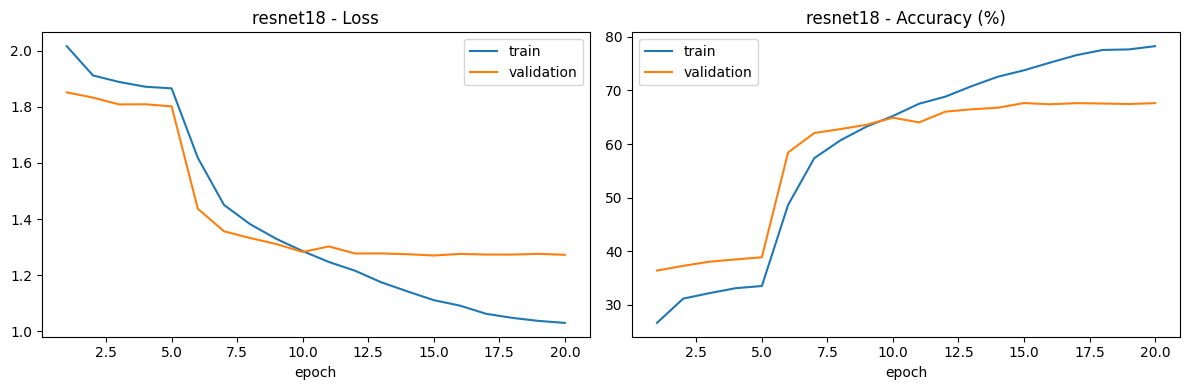

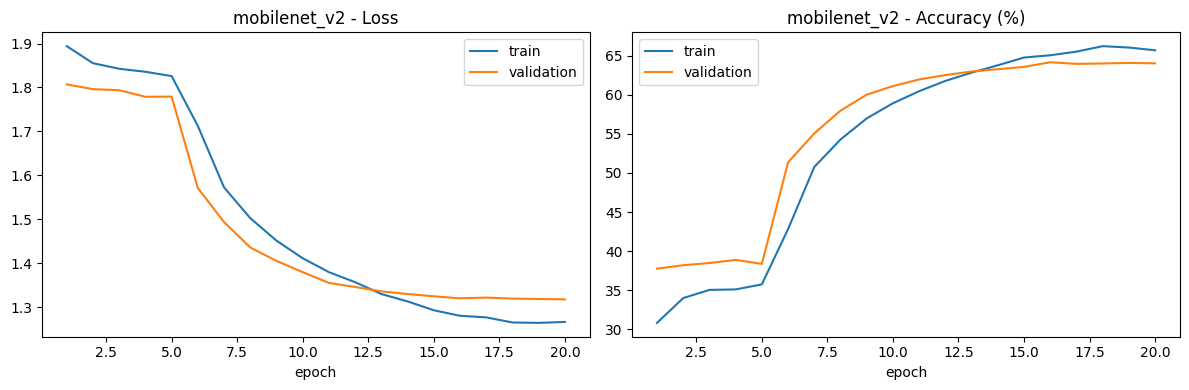

In [ ]:
for model_name, history in all_histories.items():
    epochs_range = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history["train_loss"], label="train")
    plt.plot(epochs_range, history["val_loss"], label="validation")
    plt.title(f"{model_name} - Loss")
    plt.xlabel("epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, [a * 100 for a in history["train_acc"]], label="train")
    plt.plot(epochs_range, [a * 100 for a in history["val_acc"]], label="validation")
    plt.title(f"{model_name} - Accuracy (%)")
    plt.xlabel("epoch")
    plt.legend()

    plt.tight_layout()
    plt.savefig(f"{SAVE_FOLDER}/{model_name}_training_graph.png")
    plt.show()

### Detailed evaluation: report + confusion matrix

- The **report** shows precision / recall / f1-score for every emotion.
- The **confusion matrix** shows which emotions get mixed up (rows = real emotion, columns = predicted emotion). A bright diagonal = good.

resnet18
              precision    recall  f1-score   support

       angry      0.570     0.619     0.594       958
     disgust      0.636     0.631     0.633       111
        fear      0.542     0.452     0.493      1024
       happy      0.864     0.874     0.869      1774
     neutral      0.595     0.695     0.641      1233
         sad      0.588     0.482     0.530      1247
    surprise      0.741     0.817     0.777       831

    accuracy                          0.671      7178
   macro avg      0.648     0.653     0.648      7178
weighted avg      0.667     0.671     0.666      7178



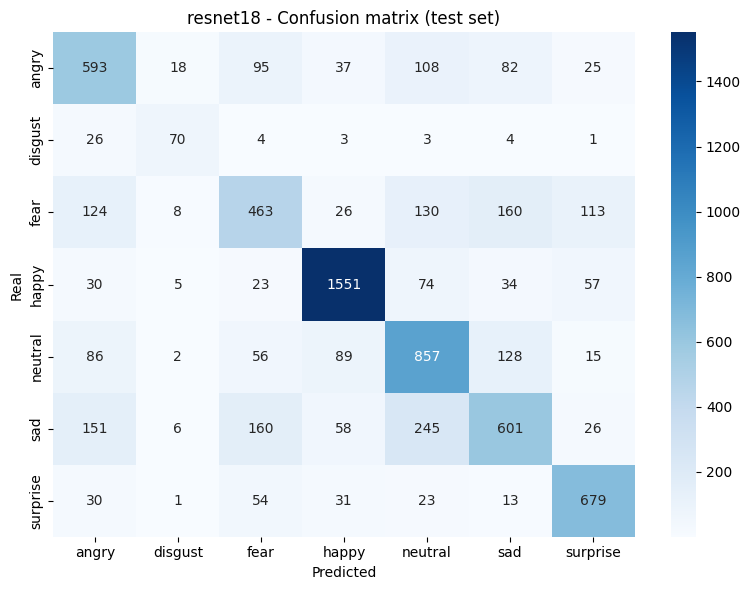

mobilenet_v2
              precision    recall  f1-score   support

       angry      0.565     0.524     0.544       958
     disgust      0.525     0.568     0.545       111
        fear      0.502     0.353     0.414      1024
       happy      0.835     0.862     0.848      1774
     neutral      0.547     0.708     0.617      1233
         sad      0.530     0.481     0.504      1247
    surprise      0.718     0.769     0.743       831

    accuracy                          0.636      7178
   macro avg      0.603     0.609     0.602      7178
weighted avg      0.631     0.636     0.629      7178



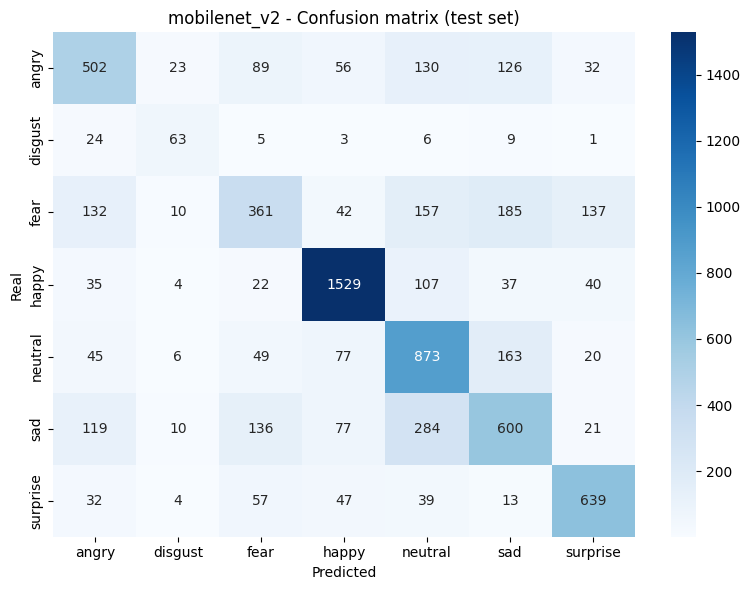

In [ ]:
for model_name in all_predictions_by_model:
    labels_true, labels_pred = all_predictions_by_model[model_name]

    print("=" * 60)
    print(model_name)
    print("=" * 60)
    print(classification_report(labels_true, labels_pred, target_names=class_names, digits=3))

    matrix = confusion_matrix(labels_true, labels_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{model_name} - Confusion matrix (test set)")
    plt.xlabel("Predicted")
    plt.ylabel("Real")
    plt.tight_layout()
    plt.savefig(f"{SAVE_FOLDER}/{model_name}_confusion_matrix.png")
    plt.show()

## Step 11: Try the saved model on some test images

This also shows you **how to load a saved model later** (for example in your Streamlit app).

Loaded: resnet18 | test accuracy: 67.07 %


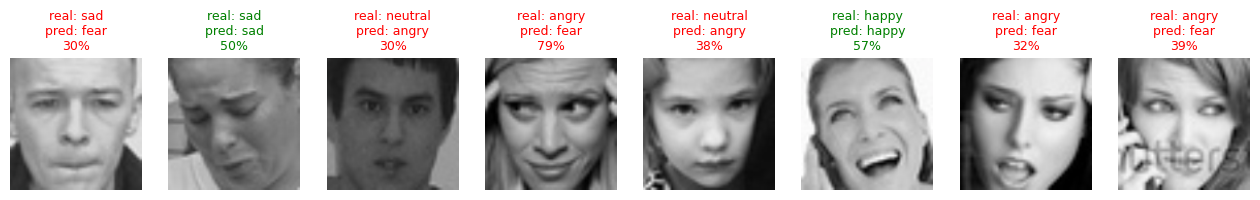

In [ ]:
# --- load the best model from the saved file ---
checkpoint = torch.load(f"{SAVE_FOLDER}/{best_model_name}_final.pth", map_location=device)
saved_name = checkpoint["model_name"]
saved_classes = checkpoint["class_names"]

# build the same model structure (without downloading pretrained weights again)
if saved_name == "resnet18":
    loaded_model = models.resnet18(weights=None)
    loaded_model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(loaded_model.fc.in_features, len(saved_classes)))
elif saved_name == "mobilenet_v2":
    loaded_model = models.mobilenet_v2(weights=None)
    loaded_model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(loaded_model.last_channel, len(saved_classes)))
else:
    loaded_model = models.efficientnet_b0(weights=None)
    loaded_model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(loaded_model.classifier[1].in_features, len(saved_classes)))

loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model = loaded_model.to(device)
loaded_model.eval()
print("Loaded:", saved_name, "| test accuracy:", round(checkpoint["test_accuracy"] * 100, 2), "%")

# --- predict 8 random test images ---
plt.figure(figsize=(16, 4))
for i in range(8):
    idx = random.randint(0, len(test_dataset) - 1)
    image_tensor, true_label = test_dataset[idx]

    with torch.no_grad():
        output = loaded_model(image_tensor.unsqueeze(0).to(device))
        probabilities = torch.softmax(output, dim=1)[0]
        predicted = probabilities.argmax().item()

    # undo the normalisation just to display the picture
    shown = image_tensor * torch.tensor(imagenet_std).view(3, 1, 1) + torch.tensor(imagenet_mean).view(3, 1, 1)
    shown = shown.permute(1, 2, 0).clamp(0, 1).numpy()

    plt.subplot(1, 8, i + 1)
    plt.imshow(shown)
    color = "green" if predicted == true_label else "red"
    plt.title(f"real: {class_names[true_label]}\npred: {class_names[predicted]}\n{probabilities[predicted] * 100:.0f}%",
              color=color, fontsize=9)
    plt.axis("off")
plt.show()

## Step 12: Save everything and download 📥

This zips the folder with **all models + graphs + results** and downloads it to your computer.

(Optional) set `BACKUP_TO_DRIVE = True` to also copy the folder to your Google Drive, so nothing is lost if Colab disconnects.

In [ ]:
# Save the class names as a small text file (useful for your app)
with open(f"{SAVE_FOLDER}/class_names.json", "w") as f:
    json.dump(class_names, f)

BACKUP_TO_DRIVE = False
if BACKUP_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copytree(SAVE_FOLDER, "/content/drive/MyDrive/emotion_models_backup", dirs_exist_ok=True)
    print("Copied to Google Drive ✅")

# Show what is inside the folder
print("Files saved:")
for name in sorted(os.listdir(SAVE_FOLDER)):
    size_mb = os.path.getsize(os.path.join(SAVE_FOLDER, name)) / (1024 * 1024)
    print(f"  {name:45s} {size_mb:6.1f} MB")

# Zip the folder and download it
shutil.make_archive("/content/emotion_models", "zip", SAVE_FOLDER)
from google.colab import files
files.download("/content/emotion_models.zip")

Files saved:
  class_names.json                                 0.0 MB
  mobilenet_v2_best.pth                            8.8 MB
  mobilenet_v2_confusion_matrix.png                0.1 MB
  mobilenet_v2_final.pth                           8.8 MB
  mobilenet_v2_training_graph.png                  0.0 MB
  resnet18_best.pth                               42.7 MB
  resnet18_confusion_matrix.png                    0.0 MB
  resnet18_final.pth                              42.7 MB
  resnet18_training_graph.png                      0.0 MB
  results_summary.csv                              0.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## ✅ What you got in the downloaded zip

| File | What it is |
|---|---|
| `<model>_final.pth` | **Use this one.** Weights + class names + image size + accuracy |
| `<model>_best.pth` | Only the weights of the best epoch |
| `results_summary.csv` | Test accuracy comparison of all models |
| `<model>_training_graph.png` | Loss / accuracy curves |
| `<model>_confusion_matrix.png` | Which emotions get confused |
| `class_names.json` | The emotion names in the right order |

## 💡 If you want even better accuracy
- Increase `IMAGE_SIZE` to `160` or `224` (slower, but often better).
- Increase `FINE_TUNE_EPOCHS` to `25`.
- Add `"efficientnet_b0"` to `MODELS_TO_TRAIN`.
- Set `USE_CLASS_WEIGHTS = False` if you care only about overall accuracy (weights help rare emotions like *disgust* but can lower overall accuracy a little).
- Look at the confusion matrix: emotions like *fear* vs *sad* and *disgust* (very few images) are the hardest, even for humans. On FER2013-style data, around **65–72% test accuracy** is already a strong result.